# MyFinSight 분석 결과 한눈에 보기

`output/13_results.json` 하나만 읽어서, 파이프라인이 **무엇을 받아(요청) → 어떻게 이해하고(의도) → 어떤 종목을 골라(선정) → 어떻게 나누고(구성) → 과거에 적용하면 어땠고(백테스트) → 기준을 통과했는지(검증)** 를 순서대로 보여줍니다.
각 절의 표와 그래프는 모두 같은 결과 파일의 숫자입니다.

In [1]:
import json, math
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl

mpl.rcParams["font.family"] = "AppleGothic"      # macOS 한글 폰트 (다른 OS: 'Malgun Gothic' / 'NanumGothic')
mpl.rcParams["axes.unicode_minus"] = False
pd.set_option("display.max_colwidth", 80); pd.set_option("display.width", 160)

import os
RESULTS = Path(os.environ.get("MYFINSIGHT_RESULTS", "../output/13_results.json"))   # 기본: notebooks/ 기준 상대 경로
R = json.loads(RESULTS.read_text(encoding="utf-8"))
pct = lambda x: "–" if x is None else f"{x*100:+.2f}%"
pct1 = lambda x: "–" if x is None else f"{x*100:.1f}%"
usd = lambda x: "–" if x is None else f"{x:,.2f} USD"
krw = lambda x: "–" if x is None else f"{x:,.0f}원"
print("request_id:", R["request_id"], "| generated:", R["generated_at"], "| pipeline:", R["pipeline_version"])

request_id: req_2026-10-10_def1 | generated: 2026-10-10T11:27:05 | pipeline: mockup-2026.10


## 1. 요청 — 사용자가 입력한 것

In [2]:
q, d, c, h, r = R["request"], R["request"]["derived"], R["request"]["capital"], R["request"]["horizon"], R["request"]["risk"]
rows = [("투자금", f"{c['initial_amount']:,.0f}원 → {usd(d['initial_amount_usd'])}  (환율 {R['money_krw']['direction']}, {d['fx_date']})"),
        ("월 적립", f"{c['monthly_contribution']:,.0f}원 (매월 {c['contribution_day']}일) → {usd(d['monthly_contribution_usd'])}"),
        ("투자기간", f"{h['target_years']}년, 시작 희망일 {h['start_date']}"),
        ("투자성향", f"{r['risk_tolerance']} · 손실 감내 수준 {r['max_drawdown_tolerance']:.0%} · 손실 시 {r['loss_reaction']}"),
        ("목표 수익률 / 비교지수", f"연 {r['target_annual_return']:.0%} / {r['benchmark']}"),
        ("전략 템플릿 / 기준 비중", f"{q['strategy_preference']['template']} / {q['strategy_preference']['baseline_weighting']}"),
        ("투자 아이디어", q["natural_language"]["idea"])]
pd.DataFrame(rows, columns=["항목", "내용"]).set_index("항목")

,내용
항목,
투자금,"30,000,000원 → 22,387.73 USD (환율 1 USD = 1,340.02 KRW, 2026-10-09)"
월 적립,"1,000,000원 (매월 25일) → 746.26 USD"
투자기간,"10.0년, 시작 희망일 2026-10-09"
투자성향,conservative · 손실 감내 수준 25% · 손실 시 hold
목표 수익률 / 비교지수,연 8% / SPY
전략 템플릿 / 기준 비중,low_volatility / inverse_volatility
투자 아이디어,"은퇴 자금이라 크게 잃지 않는 게 가장 중요합니다. 경기가 나빠져도 사람들이 계속 쓰는 생활필수품, 전기·가스·수도 같은 유틸리티, 통신..."


## 2. 의도 해석 — 분석 모델이 아이디어를 어떻게 이해했나

In [3]:
I = R["intent"]
print(I["interpretation"]["summary_ko"]); print()
themes = pd.DataFrame([{"테마": t["label_ko"], "설명": t["description_ko"], "GICS 코드": ", ".join(t["gics_codes"]), "키워드": ", ".join(t["keywords"][:6])} for t in I["interpretation"]["themes"]])
display(themes.set_index("테마"))
cons = q["constraints"]
display(pd.DataFrame([("종목 수", f"목표 {cons['num_holdings']['target']} (허용 {cons['num_holdings']['min']}~{cons['num_holdings']['max']})"), ("종목당 상한", f"{cons['max_weight_per_stock']:.0%}"), ("섹터당 상한", f"{cons['max_weight_per_sector']:.0%}"),
                      ("리밸런싱", d["rebalance_rule"]["description_ko"]), ("제외 테마", ", ".join(cons["exclude_themes"]) or "없음"),
                      ("변동성 선호 / 허용 MDD", f"{I['risk_params']['volatility_preference']} / {I['risk_params']['effective_max_drawdown']:.0%}"), ("해석 메모", I["risk_params"]["notes_ko"])], columns=["항목", "값"]).set_index("항목"))
if I["interpretation"]["conflicts"]:
    display(pd.DataFrame(I["interpretation"]["conflicts"]).rename(columns={"field": "항목", "issue_ko": "확인한 점", "resolution_ko": "처리"}))

은퇴를 위한 10년 이상 장기 투자로, 경기 상황과 관계없이 수요가 유지되는 생활필수품·유틸리티·통신·보험 기업 중 현금흐름과 배당이 비교적 안정적이고 주가 변동이 작은 대형주를 선호합니다. 명시된 스크린은 저변동성 템플릿이며, 종목 수는 15개로 하고 한 종목 비중은 10%를 넘지 않도록 합니다.



,설명,GICS 코드,키워드
테마,,,
생활필수품,"식품 소매·유통, 포장식품, 무알코올 음료, 가정용품 및 개인용품처럼 경기가 나빠져도 소비 수요가 비교적 꾸준히 유지되는 기업입니다.","301010, 30202030, 30201030, 30301010, 30302010","packaged foods, food retail, food distribution, consumer staples, household ..."
전기·가스·수도 유틸리티,"가정과 기업에 전기, 천연가스, 수도 서비스를 공급하는 규제형 전력·가스·수도 및 복합 유틸리티 기업입니다.","55101010, 55102010, 55103010, 55104010","electric utility, electric power distribution, regulated utility, natural ga..."
통신 서비스,유선·무선 통신망과 이동통신 서비스를 운영하며 가입자 기반과 반복적인 서비스 매출을 보유한 통신 사업자입니다.,"50101020, 50102010","telecommunications services, wireless telecommunications, integrated telecom..."
보험,"생명·건강, 손해보험, 종합보험, 재보험 및 보험 중개 사업을 통해 보험료 기반 매출과 장기적인 현금흐름을 창출하는 기업입니다.","40301010, 40301020, 40301030, 40301040, 40301050","insurance, property and casualty insurance, life insurance, health insurance..."


,값
항목,
종목 수,목표 15 (허용 10~20)
종목당 상한,10%
섹터당 상한,40%
리밸런싱,1×분기마다 리밸런싱
제외 테마,"tobacco, gambling, weapons"
변동성 선호 / 허용 MDD,low / 25%
해석 메모,손실 발생 시 hold로 응답했고 투자 경험도 none이 아니므로 허용 최대 낙폭은 입력값 0.25를 그대로 적용합니다. 보수적 위험 성...


,항목,확인한 점,처리
0,strategy_preference.template / natural_language.idea,"자연어 아이디어는 꾸준한 배당을 선호하지만, 명시된 전략 템플릿은 high_dividend가 아니라 low_volatility입니다.","명시된 템플릿을 우선해 60거래일 변동성 기준으로 스크린하고, 배당 선호는 테마 설명과 종목 분류에 반영합니다."


## 3. 종목 선정 — 깔때기와 선정 표

유니버스 → 테마 관련 후보(GICS·키워드) → 테마 해당 판정(분석 모델) → 선정 지표 순위 → 섹터 상한 → 최종. 백테스트는 시작일 당시 정보로 같은 규칙을 다시 적용하므로 목록이 다를 수 있습니다.

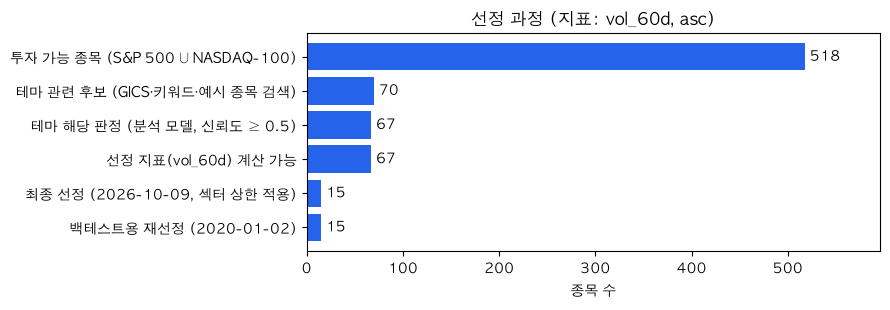

,회사,섹터,테마,신뢰도,순위(2020-01-02),지표(백테스트),순위(2026-10-09),지표(2026),테마 판정 사유
티커,,,,,,,,,
PEP,PepsiCo,Consumer Staples,consumer_essentials,0.95,1.0,+8.89%,NaN,+nan%,무알코올 음료와 포장식품을 대규모로 판매
SYY,Sysco,Consumer Staples,consumer_essentials,0.85,2.0,+9.64%,15.0,+18.57%,식당과 기관에 식품을 유통·공급하는 사업자
WMT,Walmart,Consumer Staples,consumer_essentials,0.75,3.0,+9.97%,NaN,+nan%,식료품과 생활용품을 대규모로 판매하는 소매업체
D,Dominion Energy,Utilities,regulated_utilities,0.90,4.0,+10.66%,3.0,+14.23%,전력·가스 공급을 중심으로 하는 규제형 복합 유틸리티
VZ,Verizon,Communication Services,telecommunications,0.95,5.0,+10.67%,NaN,+nan%,무선·유선 통신망을 운영하며 반복 서비스 매출을 창출
COST,Costco,Consumer Staples,consumer_essentials,0.80,6.0,+11.03%,10.0,+17.00%,창고형 매장에서 식품과 생활필수 소비재를 대량 소매
PEG,Public Service Enterprise Group,Utilities,regulated_utilities,0.90,7.0,+11.06%,NaN,+nan%,전기·가스 유틸리티 사업을 운영
FE,FirstEnergy,Utilities,regulated_utilities,0.95,8.0,+11.35%,6.0,+14.49%,전력 배전과 송전을 담당하는 전력 유틸리티
KO,Coca-Cola Company (The),Consumer Staples,consumer_essentials,0.95,9.0,+11.56%,NaN,+nan%,콜라 등 무알코올 음료를 제조·판매


백테스트 재선정에서 추가: ['AEP', 'AJG', 'ALL', 'DG', 'DUK', 'ED', 'KO', 'PEG', 'PEP', 'VZ', 'WMT'] | 빠짐: ['AEE', 'AFL', 'AIG', 'ATO', 'CINF', 'CL', 'L', 'NEE', 'PG', 'PRU', 'SO']


,회사,제외 이유,지표값
티커,,,
WRB,W. R. Berkley Corporation,rank_beyond_n,0.187622
AWK,American Water Works,rank_beyond_n,0.188487
PEP,PepsiCo,rank_beyond_n,0.189174
CHD,Church & Dwight,rank_beyond_n,0.192230
KO,Coca-Cola Company (The),rank_beyond_n,0.193030
KVUE,Kenvue,rank_beyond_n,0.194069
CB,Chubb Limited,rank_beyond_n,0.195516
HIG,Hartford (The),rank_beyond_n,0.196632


In [4]:
S = R["selection"]
f = pd.DataFrame(S["funnel"])
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.barh(f["label_ko"][::-1], f["count"][::-1], color="#2563eb")
for i, v in enumerate(f["count"][::-1]): ax.text(v + 5, i, str(v), va="center")
ax.set_xlabel("종목 수"); ax.set_title(f"선정 과정 (지표: {S['metric']}, {S['direction']})"); ax.set_xlim(0, f["count"].max() * 1.15)
plt.tight_layout(); plt.show()

t = pd.DataFrame(S["table"])
view = t[["ticker", "name", "sector", "themes", "theme_confidence", "rank_backtest", "metric_backtest", "rank_2026", "metric_2026", "theme_reason_ko"]].copy()
view["themes"] = view["themes"].str.join(", "); view["metric_backtest"] = view["metric_backtest"].map(pct); view["metric_2026"] = view["metric_2026"].map(pct)
view.columns = ["티커", "회사", "섹터", "테마", "신뢰도", f"순위({S['backtest_as_of']['as_of']})", "지표(백테스트)", f"순위({S['as_of_2026']['as_of']})", "지표(2026)", "테마 판정 사유"]
display(view.set_index("티커"))
diff = S["backtest_as_of"]["diff_vs_original"]
print("백테스트 재선정에서 추가:", diff["added"], "| 빠짐:", diff["removed"])
display(pd.DataFrame(S["as_of_2026"]["rejected_examples"]).rename(columns={"ticker": "티커", "name": "회사", "reason": "제외 이유", "metric_value": "지표값"}).set_index("티커"))

## 4. 포트폴리오 구성 — 기준 비중, 규칙 4가지, 시나리오 5개

기준은 1/N 동일비중이고, 종목·섹터 상한으로 재배분합니다. Black-Litterman 타겟은 기준 비중에 시나리오 뷰를 종목당 최대 `max_tilt` 만큼만 반영한 것입니다.

,섹터,1/N,최종 비중
PEP,Consumer Staples,6.7%,7.9%
SYY,Consumer Staples,6.7%,6.4%
WMT,Consumer Staples,6.7%,6.0%
D,Utilities,6.7%,6.5%
VZ,Communication Services,6.7%,6.5%
COST,Consumer Staples,6.7%,6.0%
PEG,Utilities,6.7%,6.6%
FE,Utilities,6.7%,5.7%
KO,Consumer Staples,6.7%,8.1%
AJG,Financials,6.7%,7.4%


적용된 제약: ['sector_cap:Utilities'] | 섹터 비중: {'Consumer Staples': 0.394, 'Utilities': 0.4, 'Communication Services': 0.065, 'Financials': 0.141}


,설명,예상 변동성,유효 종목 수,최대 비중
규칙,,,,
동일비중,모든 종목에 같은 비중 1/N,9.9%,15.0,6.7%
시가총액비중,시가총액에 비례한 비중 (지수 방식),10.0%,12.8,10.0%
역변동성비중,변동성이 낮은 종목에 더 큰 비중 (1/σ 정규화),9.8%,14.8,8.1%
최소분산,포트폴리오 분산을 최소화하는 비중 (제약 포함 최적화),9.7%,12.4,10.0%


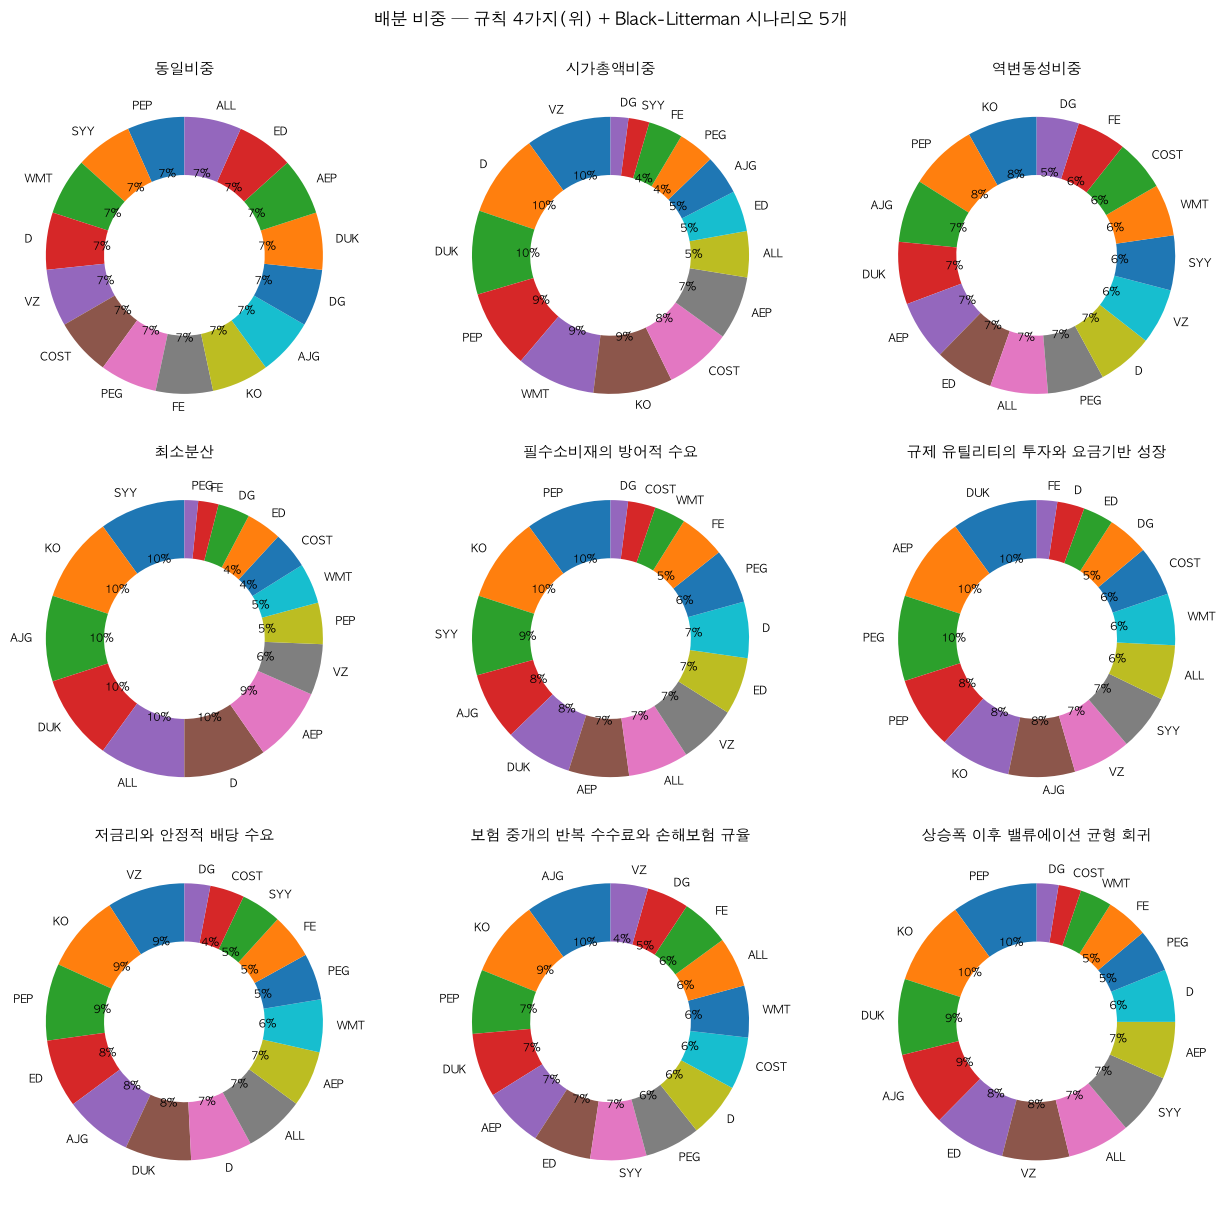

In [5]:
P = R["portfolio"]; base = next(p for p in P["baselines"]["portfolios"] if p["id"] == P["baselines"]["chosen_baseline"])
n = len(base["weights"]); sec = {x["ticker"]: x["sector"] for x in S["table"]}
bt_ = pd.DataFrame({"섹터": {t: sec.get(t, "") for t in base["weights"]}, "1/N": {t: 1/n for t in base["weights"]}, "최종 비중": base["weights"]})
display(bt_.style.format({"1/N": "{:.1%}", "최종 비중": "{:.1%}"}))
print("적용된 제약:", base["constraints_applied"], "| 섹터 비중:", {k: round(v, 3) for k, v in base["sector_weights"].items()})

tmpl = pd.DataFrame([{"규칙": p["name_ko"], "설명": p["rule_ko"], "예상 변동성": p["ex_ante"]["vol"], "유효 종목 수": p["ex_ante"]["effective_n"], "최대 비중": max(p["weights"].values())} for p in P["baselines"]["portfolios"]])
display(tmpl.set_index("규칙").style.format({"예상 변동성": "{:.1%}", "최대 비중": "{:.1%}", "유효 종목 수": "{:.1f}"}))

ports = P["baselines"]["portfolios"] + P["targets"]["portfolios"]
fig, axes = plt.subplots(3, 3, figsize=(13, 12))
for ax, p in zip(axes.flat, ports):
    items = sorted([(t, w) for t, w in p["weights"].items() if w > 1e-6], key=lambda x: -x[1])
    ax.pie([w for _, w in items], labels=[t for t, _ in items], startangle=90, wedgeprops=dict(width=0.42), textprops={"fontsize": 8}, autopct=lambda v: f"{v:.0f}%" if v > 4 else "")
    ax.set_title(p.get("title_ko") or p["name_ko"], fontsize=11)
plt.suptitle("배분 비중 — 규칙 4가지(위) + Black-Litterman 시나리오 5개", y=1.0); plt.tight_layout(); plt.show()

,관점,뷰,최대 변화,예상 수익,예상 변동성
시나리오,,,,,
필수소비재의 방어적 수요,경기 불확실성이 커져도 식음료와 생필품 수요는 비교적 꾸준히 유지될 수 있습니다. 이 시나리오에서는 반복 구매와 브랜드 경쟁력을 갖춘 필수소비재에 무게를 둡니다.,[절대] PEP +9%/년 (신뢰 0.22) / [절대] KO +8%/년 (신뢰 0.20) / [상대] PEP+KO > DG+COST +8%/년 (신뢰 0.19) / [상대] SYY > WMT +6%/년 (신뢰 0.16),+2.9%,7.8%,10.0%
규제 유틸리티의 투자와 요금기반 성장,전력망과 설비 투자가 지속되고 규제 요금기반에 반영된다면 유틸리티의 완만한 성장이 가능할 수 있습니다. 이 포트폴리오 관점에서는 투자 회수와 재무 안정성을 갖춘 전력 사업자를 선호합니다.,[절대] PEG +9%/년 (신뢰 0.20) / [절대] AEP +9%/년 (신뢰 0.19) / [상대] PEG+AEP > FE+D +7%/년 (신뢰 0.17) / [상대] DUK > ED +5%/년 (신뢰 0.14),+3.3%,7.9%,10.0%
저금리와 안정적 배당 수요,금리가 낮게 유지되면 배당과 예측 가능한 현금흐름을 제공하는 유틸리티·통신주의 매력이 높아질 수 있습니다. 다만 금리에 민감한 종목의 밸류에이션 변동을 감안해 안정적인 사업 기반을 중심으로 접근합니다.,[절대] VZ +8%/년 (신뢰 0.20) / [절대] ED +8%/년 (신뢰 0.18) / [상대] VZ+ED > DG+COST +7%/년 (신뢰 0.16) / [상대] DUK+D > SYY +6%/년 (신뢰 0.15),+2.6%,7.7%,10.0%
보험 중개의 반복 수수료와 손해보험 규율,"보험 중개는 보험료 기반 수수료와 위험관리 서비스가 수익의 반복성을 높일 수 있고, 손해보험사는 인수 규율과 손해율 관리가 중요합니다. 이 시나리오에서는 중개 사업의 가시성을 우선하되 보험사의 수익성 개선 가능성도 반영합니다.",[절대] AJG +8%/년 (신뢰 0.20) / [절대] ALL +8%/년 (신뢰 0.16) / [상대] AJG > ALL +7%/년 (신뢰 0.18) / [상대] ALL > VZ +5%/년 (신뢰 0.13),+2.6%,7.8%,10.0%
상승폭 이후 밸류에이션 균형 회귀,직전 12개월 상승폭이 큰 일부 소매주는 사업의 질과 별개로 기대치와 밸류에이션 부담이 커질 수 있습니다. 이 관점에서는 필수소비재의 안정성은 유지하면서 상대적으로 방어적인 유틸리티와 브랜드 식품주로 균형을 둡니다.,[절대] COST +6%/년 (신뢰 0.15) / [절대] DG +6%/년 (신뢰 0.14) / [상대] ED+DUK > COST+DG +9%/년 (신뢰 0.18) / [상대] PEP+KO > WMT+COST +7%/년 (신뢰 0.17),+3.3%,7.7%,10.0%


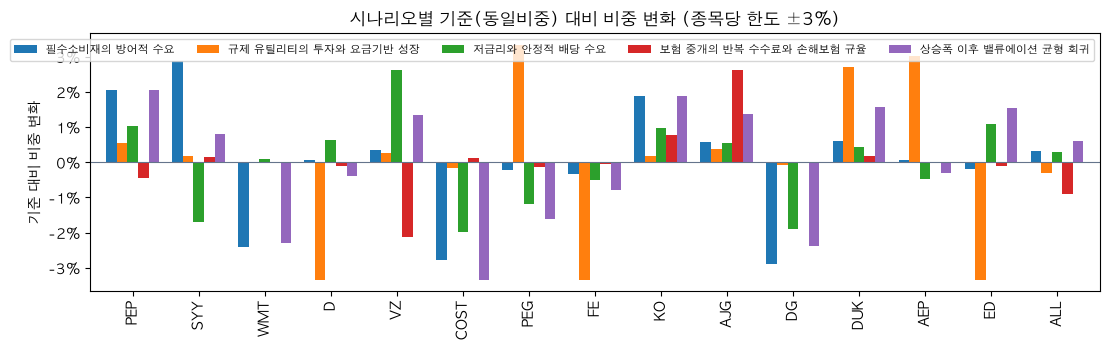

In [6]:
sc = pd.DataFrame([{"시나리오": p["title_ko"], "관점": p["portfolio_view"].split("\n")[0], "뷰": " / ".join(v["summary_ko"].split(" — ")[0] for v in p["views_applied"]),
                    "최대 변화": max(abs(x) for x in p["delta_vs_baseline"].values()), "예상 수익": p["ex_ante"]["exp_return"], "예상 변동성": p["ex_ante"]["vol"]} for p in P["targets"]["portfolios"]])
display(sc.set_index("시나리오").style.format({"최대 변화": "{:+.1%}", "예상 수익": "{:.1%}", "예상 변동성": "{:.1%}"}))
dl = pd.DataFrame({p["title_ko"]: p["delta_vs_baseline"] for p in P["targets"]["portfolios"]})
ax = dl.plot.bar(figsize=(12, 3.6), width=0.8); ax.axhline(0, color="#64748b", lw=0.8); ax.set_ylabel("기준 대비 비중 변화"); ax.yaxis.set_major_formatter(mpl.ticker.PercentFormatter(1.0, decimals=0))
ax.set_title(f"시나리오별 기준(동일비중) 대비 비중 변화 (종목당 한도 ±{P['targets']['parameters']['max_tilt_per_stock']:.0%})"); ax.legend(ncol=5, fontsize=8); plt.tight_layout(); plt.show()

## 5. 백테스트 — 같은 기간·같은 적립으로 9개 포트폴리오와 비교지수를 돌린 결과

In [7]:
BT = R["backtest"]; rec = R["validation"].get("recommended"); chosen = rec["id"] if rec else P["targets"]["baseline"]["id"]
label = lambda p: (f"시나리오: {p['title_ko']}" if p.get("title_ko") else p["name_ko"])
E = BT["engine"]; print(f"기간 {BT['period']['start']}~{BT['period']['end']} ({BT['period']['trading_days']}거래일) · 적립 {E['n_contributions']}회 × {E['contribution_usd']:.0f} USD · 거래비용 {E['commission_bps']}bp · 무위험 {E['risk_free_rate']:.0%} · {E['prices']}")
print("중심 포트폴리오:", chosen, "(추천)" if rec else "(추천 없음 → 기준 포트폴리오)")
rows = []
for p in [*BT["portfolios"], *BT.get("benchmarks", [BT["benchmark"]]), *R["validation"].get("alternatives", [])]:
    h, m = p["headline"], p["metrics"]
    rows.append({"포트폴리오": label(p), "종류": p["kind"], "누적수익": m["return"]["total_return"], "CAGR": h["cagr"], "변동성": m["risk"]["ann_vol"], "Sharpe": h["sharpe"], "최대낙폭": h["max_drawdown"],
                 "SPY 대비": h["excess_cagr"], "최종 평가금액": h["final_value_usd"], "투입 원금": p["money"]["net_invested_usd"], "XIRR": p["money"]["irr_annual"], "뷰 적중": h["view_hit_ratio"]})
comp = pd.DataFrame(rows).set_index("포트폴리오")
display(comp.style.format({"누적수익": "{:+.1%}", "CAGR": "{:+.1%}", "변동성": "{:.1%}", "Sharpe": "{:.2f}", "최대낙폭": "{:.1%}", "SPY 대비": "{:+.1%}", "최종 평가금액": "{:,.0f}", "투입 원금": "{:,.0f}", "XIRR": "{:+.1%}", "뷰 적중": "{:.0%}"}, na_rep="–").background_gradient(subset=["Sharpe"], cmap="Blues"))

기간 2020-01-02~2026-10-09 (1702거래일) · 적립 80회 × 867 USD · 거래비용 5bp · 무위험 4% · adj_close (dividends reinvested)
중심 포트폴리오: inverse_volatility (추천 없음 → 기준 포트폴리오)


,종류,누적수익,CAGR,변동성,Sharpe,최대낙폭,SPY 대비,최종 평가금액,투입 원금,XIRR,뷰 적중
포트폴리오,,,,,,,,,,,
시나리오: 필수소비재의 방어적 수요,black_litterman,+71.0%,+8.3%,17.8%,0.24,-32.5%,-7.0%,"138,383","95,323",+8.7%,25%
시나리오: 규제 유틸리티의 투자와 요금기반 성장,black_litterman,+82.0%,+9.3%,17.2%,0.31,-30.4%,-6.0%,"143,420","95,323",+9.5%,50%
시나리오: 저금리와 안정적 배당 수요,black_litterman,+75.2%,+8.7%,17.3%,0.27,-30.2%,-6.6%,"140,892","95,323",+9.1%,50%
시나리오: 보험 중개의 반복 수수료와 손해보험 규율,black_litterman,+83.1%,+9.4%,17.4%,0.31,-30.7%,-5.9%,"143,981","95,323",+9.6%,50%
시나리오: 상승폭 이후 밸류에이션 균형 회귀,black_litterman,+71.8%,+8.3%,17.6%,0.25,-31.9%,-7.0%,"138,698","95,323",+8.7%,0%
동일비중,template,+78.9%,+9.0%,17.3%,0.29,-29.5%,-6.3%,"142,566","95,323",+9.4%,–
시가총액비중,template,+79.4%,+9.0%,17.1%,0.29,-27.9%,-6.3%,"143,544","95,323",+9.5%,–
역변동성비중,template,+78.7%,+9.0%,17.3%,0.29,-30.2%,-6.3%,"142,360","95,323",+9.3%,–
최소분산,template,+80.4%,+9.1%,17.8%,0.29,-32.3%,-6.2%,"144,066","95,323",+9.6%,–


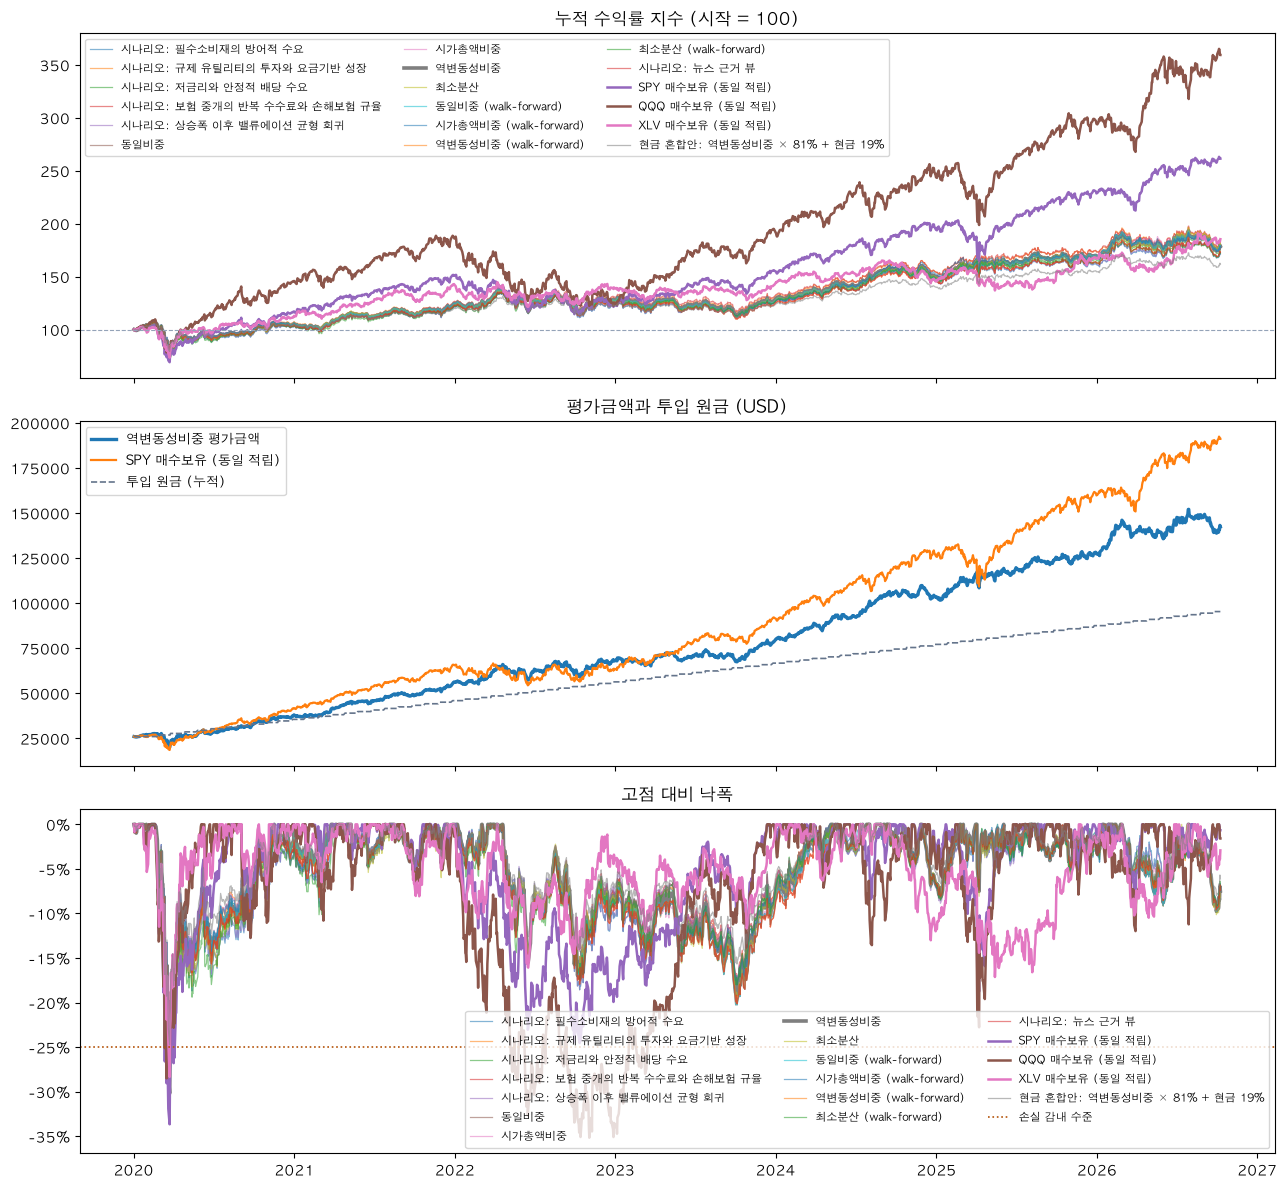

역변동성비중 최대낙폭 -30.2%: 고점 2020-02-18 → 저점 2020-03-23 → 회복 2020-11-16 (고점 아래 272일)


In [8]:
dates = pd.to_datetime(BT["series_dates"]); series = {p["id"]: p for p in [*BT["portfolios"], *BT.get("benchmarks", [BT["benchmark"]]), *R["validation"].get("alternatives", [])]}
fig, axes = plt.subplots(3, 1, figsize=(13, 12), sharex=True)
for pid, p in series.items():
    lw = 2.6 if pid == chosen else (1.8 if p["kind"] == "benchmark" else 0.9); alpha = 1 if (pid == chosen or p["kind"] == "benchmark") else 0.55
    axes[0].plot(dates, p["series"]["index"], lw=lw, alpha=alpha, label=label(p))
    axes[2].plot(dates, p["series"]["drawdown"], lw=lw, alpha=alpha, label=label(p))
axes[0].axhline(100, color="#94a3b8", ls="--", lw=0.8); axes[0].set_title("누적 수익률 지수 (시작 = 100)"); axes[0].legend(ncol=3, fontsize=8)
cp = series[chosen]; led = {l["date"]: l["amount_usd"] for l in cp["contribution_ledger"]}; inv, cum = [], cp["money"]["initial_usd"]
for ds in BT["series_dates"]: cum += led.get(ds, 0.0); inv.append(cum)
axes[1].plot(dates, cp["series"]["value_usd"], lw=2.4, label=f"{label(cp)} 평가금액"); axes[1].plot(dates, series[BT["benchmark"]["id"]]["series"]["value_usd"], lw=1.6, label="SPY 매수보유 (동일 적립)")
axes[1].plot(dates, inv, lw=1.2, ls="--", color="#64748b", label="투입 원금 (누적)"); axes[1].set_title("평가금액과 투입 원금 (USD)"); axes[1].legend(fontsize=9)
axes[2].yaxis.set_major_formatter(mpl.ticker.PercentFormatter(1.0, decimals=0)); axes[2].set_title("고점 대비 낙폭"); axes[2].axhline(-R["intent"]["risk_params"]["effective_max_drawdown"], color="#b45309", ls=":", lw=1.2, label="손실 감내 수준")
axes[2].legend(ncol=3, fontsize=8); plt.tight_layout(); plt.show()
mdd = cp["metrics"]["risk"]["mdd"]; print(f"{label(cp)} 최대낙폭 {cp['headline']['max_drawdown']:.1%}: 고점 {mdd['peak_date']} → 저점 {mdd['trough_date']} → 회복 {mdd['recovery_date'] or '기간 내 미회복'} (고점 아래 {mdd['underwater_days']}일)")

,2020,2021,2022,2023,2024,2025,2026
역변동성비중,+5.7%,+17.8%,+2.2%,+0.2%,+17.5%,+12.7%,+5.8%
SPY 매수보유 (동일 적립),+17.1%,+28.7%,-18.2%,+26.2%,+24.9%,+17.7%,+14.4%


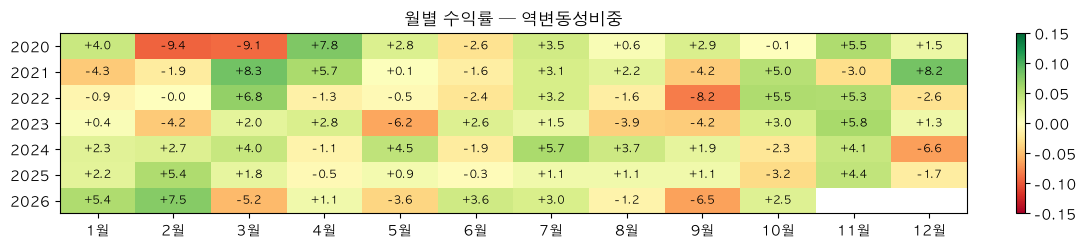

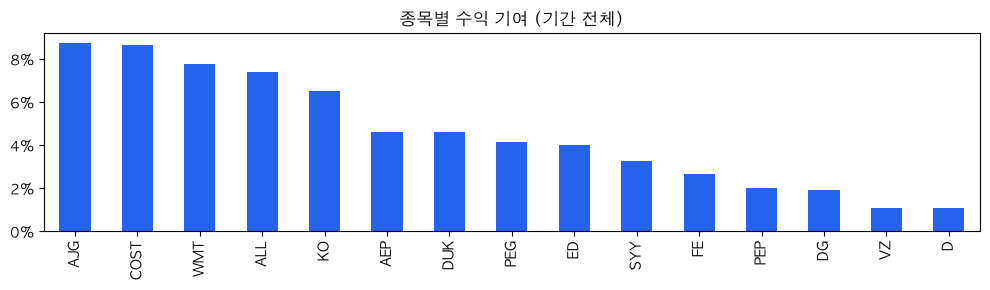

In [9]:
yr = pd.DataFrame({label(p): p["yearly_returns"] for p in [cp, series[BT["benchmark"]["id"]], series[P["targets"]["baseline"]["id"]]]}).T
display(yr.style.format("{:+.1%}", na_rep="–").set_caption("연도별 수익률 (첫해·마지막 해는 부분 기간)"))
mr = pd.DataFrame(cp["monthly_returns"]).pivot(index="year", columns="month", values="return")
fig, ax = plt.subplots(figsize=(11, 2.6)); im = ax.imshow(mr.values, cmap="RdYlGn", vmin=-0.15, vmax=0.15, aspect="auto")
ax.set_xticks(range(12)); ax.set_xticklabels([f"{m}월" for m in range(1, 13)]); ax.set_yticks(range(len(mr.index))); ax.set_yticklabels(mr.index)
for i in range(mr.shape[0]):
    for j in range(mr.shape[1]):
        v = mr.values[i, j]
        if not np.isnan(v): ax.text(j, i, f"{v*100:+.1f}", ha="center", va="center", fontsize=8)
ax.set_title(f"월별 수익률 — {label(cp)}"); plt.colorbar(im, ax=ax, fraction=0.02); plt.tight_layout(); plt.show()
contrib = pd.Series(cp["ticker_contribution"]).sort_values(ascending=False)
ax = contrib.plot.bar(figsize=(10, 3), color=["#2563eb" if v >= 0 else "#b45309" for v in contrib]); ax.yaxis.set_major_formatter(mpl.ticker.PercentFormatter(1.0, decimals=0)); ax.set_title("종목별 수익 기여 (기간 전체)"); plt.tight_layout(); plt.show()

### 리밸런싱 시점별 구성과 성과
각 리밸런싱일의 **조정 후 비중**(행)과 그 **직전 구간 성과**, 그 시점까지의 누적 지표입니다.

In [10]:
cps = cp["checkpoints"]
wt = pd.DataFrame({c["date"]: c["weights"]["after"] for c in cps}).T
display(wt.style.format("{:.1%}").background_gradient(cmap="Blues", axis=None).set_caption(f"리밸런싱 후 비중 — {label(cp)}"))
rows = []
for c in cps:
    sl, td = c["since_last"] or {}, c["to_date"] or {}
    rows.append({"날짜": c["date"], "구분": c["kind"], "평가금액": c["money"]["value_usd"], "투입 원금": c["money"]["net_invested_usd"], "구간 수익": sl.get("return"), "SPY 구간": sl.get("benchmark_return"),
                 "구간 최대낙폭": sl.get("max_drawdown"), "최고 종목": f"{sl['best']['ticker']} {sl['best']['return']:+.1%}" if sl else "", "최저 종목": f"{sl['worst']['ticker']} {sl['worst']['return']:+.1%}" if sl else "",
                 "누적 CAGR": td.get("cagr"), "누적 MDD": td.get("max_drawdown"), "누적 Sharpe": td.get("sharpe"), "거래": len(c["trades"]), "비용": c["commission_usd"]})
display(pd.DataFrame(rows).set_index("날짜").style.format({"평가금액": "{:,.0f}", "투입 원금": "{:,.0f}", "구간 수익": "{:+.1%}", "SPY 구간": "{:+.1%}", "구간 최대낙폭": "{:.1%}", "누적 CAGR": "{:+.1%}", "누적 MDD": "{:.1%}", "누적 Sharpe": "{:.2f}", "비용": "{:.2f}"}, na_rep="–"))

,PEP,SYY,WMT,D,VZ,COST,PEG,FE,KO,AJG,DG,DUK,AEP,ED,ALL
2020-01-02,7.9%,6.4%,6.0%,6.5%,6.5%,6.0%,6.6%,5.7%,8.1%,7.4%,4.9%,7.3%,7.0%,6.9%,6.7%
2020-04-01,7.9%,6.4%,6.0%,6.5%,6.5%,6.0%,6.6%,5.7%,8.1%,7.4%,4.9%,7.3%,7.0%,6.9%,6.7%
2020-07-01,7.9%,6.4%,6.0%,6.5%,6.5%,6.0%,6.6%,5.7%,8.1%,7.4%,4.9%,7.3%,7.0%,6.9%,6.7%
2020-10-01,7.9%,6.4%,6.0%,6.5%,6.5%,6.0%,6.6%,5.7%,8.1%,7.4%,4.9%,7.3%,7.0%,6.9%,6.7%
2021-01-04,7.9%,6.4%,6.0%,6.5%,6.5%,6.0%,6.6%,5.7%,8.1%,7.4%,4.9%,7.3%,7.0%,6.9%,6.7%
2021-04-01,7.9%,6.4%,6.0%,6.5%,6.5%,6.0%,6.6%,5.7%,8.1%,7.4%,4.9%,7.3%,7.0%,6.9%,6.7%
2021-07-01,7.9%,6.4%,6.0%,6.5%,6.5%,6.0%,6.6%,5.7%,8.1%,7.4%,4.9%,7.3%,7.0%,6.9%,6.7%
2021-10-01,7.9%,6.4%,6.0%,6.5%,6.5%,6.0%,6.6%,5.7%,8.1%,7.4%,4.9%,7.3%,7.0%,6.9%,6.7%
2022-01-03,7.9%,6.4%,6.0%,6.5%,6.5%,6.0%,6.6%,5.7%,8.1%,7.4%,4.9%,7.3%,7.0%,6.9%,6.7%
2022-04-01,7.9%,6.4%,6.0%,6.5%,6.5%,6.0%,6.6%,5.7%,8.1%,7.4%,4.9%,7.3%,7.0%,6.9%,6.7%


,구분,평가금액,투입 원금,구간 수익,SPY 구간,구간 최대낙폭,최고 종목,최저 종목,누적 CAGR,누적 MDD,누적 Sharpe,거래,비용
날짜,,,,,,,,,,,,,
2020-01-02,rebalance,"25,984","25,997",–,–,–,,,–,–,–,15,12.99
2020-04-01,rebalance,"23,154","27,730",-17.0%,-23.8%,-30.2%,COST -1.4%,SYY -50.5%,-53.2%,-30.2%,-1.08,15,1.08
2020-07-01,rebalance,"28,566","30,330",+12.0%,+26.5%,-9.3%,SYY +30.7%,ED -4.8%,-13.8%,-30.2%,-0.42,15,0.90
2020-10-01,rebalance,"33,300","32,930",+7.1%,+8.9%,-3.6%,WMT +20.0%,FE -26.9%,-0.7%,-30.2%,-0.13,15,1.06
2021-01-04,rebalance,"37,279","35,529",+4.2%,+9.9%,-4.9%,ALL +17.8%,ED -9.8%,+3.6%,-30.2%,-0.01,15,1.04
2021-04-01,rebalance,"41,361","38,129",+3.7%,+9.0%,-4.9%,FE +17.7%,WMT -7.1%,+6.0%,-30.2%,0.07,15,0.96
2021-07-01,rebalance,"45,839","40,729",+4.6%,+7.8%,-4.7%,ALL +15.1%,VZ -2.4%,+8.1%,-30.2%,0.15,15,0.95
2021-10-01,rebalance,"48,741","43,329",+0.8%,+1.2%,-5.5%,COST +13.8%,FE -3.8%,+7.4%,-30.2%,0.14,15,0.89
2022-01-03,rebalance,"56,092","45,928",+9.6%,+10.4%,-4.4%,COST +26.6%,ALL -6.7%,+11.4%,-30.2%,0.31,15,1.54


In [11]:
vd = [(label(p), v["type"], v["summary_ko"].split(" — ")[0], v["expected_return_annual"], v["realized"], "적중" if v["hit"] else "빗나감") for p in BT["portfolios"] for v in p["view_diagnostics"]]
if vd:
    display(pd.DataFrame(vd, columns=["시나리오", "유형", "뷰", "기대", "실제(12개월)", "방향"]).style.format({"기대": "{:+.0%}", "실제(12개월)": "{:+.1%}"}).set_caption("시나리오 뷰 사후 점검 (구성 후 12개월 실현 수익)"))

,시나리오,유형,뷰,기대,실제(12개월),방향
0,시나리오: 필수소비재의 방어적 수요,absolute,[절대] PEP +9%/년 (신뢰 0.22),+9%,+12.4%,적중
1,시나리오: 필수소비재의 방어적 수요,absolute,[절대] KO +8%/년 (신뢰 0.20),+8%,+3.1%,빗나감
2,시나리오: 필수소비재의 방어적 수요,relative,[상대] PEP+KO > DG+COST +8%/년 (신뢰 0.19),+8%,-26.8%,빗나감
3,시나리오: 필수소비재의 방어적 수요,relative,[상대] SYY > WMT +6%/년 (신뢰 0.16),+6%,-33.1%,빗나감
4,시나리오: 규제 유틸리티의 투자와 요금기반 성장,absolute,[절대] PEG +9%/년 (신뢰 0.20),+9%,+3.0%,빗나감
5,시나리오: 규제 유틸리티의 투자와 요금기반 성장,absolute,[절대] AEP +9%/년 (신뢰 0.19),+9%,-8.0%,빗나감
6,시나리오: 규제 유틸리티의 투자와 요금기반 성장,relative,[상대] PEG+AEP > FE+D +7%/년 (신뢰 0.17),+7%,+16.0%,적중
7,시나리오: 규제 유틸리티의 투자와 요금기반 성장,relative,[상대] DUK > ED +5%/년 (신뢰 0.14),+5%,+21.3%,적중
8,시나리오: 저금리와 안정적 배당 수요,absolute,[절대] VZ +8%/년 (신뢰 0.20),+8%,+0.4%,빗나감
9,시나리오: 저금리와 안정적 배당 수요,absolute,[절대] ED +8%/년 (신뢰 0.18),+8%,-15.5%,적중


## 6. 검증 — 사용자 기준(손실 감내 수준·목표 수익·제약)에 비춰 본 판정

In [12]:
V = R["validation"]; print("기준:", {k: V["criteria"][k] for k in ["max_drawdown", "target_annual_return", "benchmark", "volatility_preference", "max_weight_per_stock", "max_weight_per_sector", "min_holdings"]})
mat = pd.DataFrame({label(series[r["id"]]): {c["rule"] + " " + c["name_ko"]: c["status"] for c in r["checks"]} for r in V["results"]}).T
color = lambda s: "background-color:#dcfce7" if s == "pass" else ("background-color:#fef3c7" if s == "warn" else "background-color:#fee2e2")
display(mat.style.map(color).set_caption("규칙별 판정 (pass 통과 / warn 주의 / fail 미통과)"))
print("요약:", V["summary"]); print("추천:", V["recommended"]["id"] + " — " + V["recommended"]["reason_ko"] if V["recommended"] else "추천 없음 — " + "; ".join(V["warnings"]))
for alt in V.get("alternatives", []): print(f"대안 {alt['name_ko']}: {alt['reason_ko']} 판정 {alt['status']}")
inf = V["criteria"].get("selection_infeasibility")
if inf: print(f"종목 수 미달 사유: 섹터 상한 {inf['sector_cap']:.0%} 로 최대 {inf['max_feasible_n']}종목 (목표 {inf['target']}); 선택지: " + " / ".join(inf["options_ko"]))
chk = pd.DataFrame(next(r for r in V["results"] if r["id"] == chosen)["checks"])[["rule", "name_ko", "level", "status", "message_ko"]]
display(chk.set_index("rule").rename(columns={"name_ko": "항목", "level": "수준", "status": "판정", "message_ko": "측정 결과"}).style.set_caption(f"{label(cp)} 상세"))

기준: {'max_drawdown': 0.25, 'target_annual_return': 0.08, 'benchmark': 'SPY', 'volatility_preference': 'low', 'max_weight_per_stock': 0.1, 'max_weight_per_sector': 0.4, 'min_holdings': 10}


,R1 최대낙폭,R2 목표수익,R3 비교지수 대비,R4 종목 상한(리밸런싱일),R4b 종목 상한(드리프트),R5 섹터 상한(리밸런싱일),R5b 섹터 상한(드리프트),R6 종목 수,R7 변동성 적합,R8 데이터 무결성
시나리오: 필수소비재의 방어적 수요,fail,pass,warn,pass,pass,pass,pass,pass,warn,pass
시나리오: 규제 유틸리티의 투자와 요금기반 성장,fail,pass,warn,pass,pass,pass,pass,pass,warn,pass
시나리오: 저금리와 안정적 배당 수요,fail,pass,warn,pass,pass,pass,pass,pass,warn,pass
시나리오: 보험 중개의 반복 수수료와 손해보험 규율,fail,pass,warn,pass,pass,pass,pass,pass,warn,pass
시나리오: 상승폭 이후 밸류에이션 균형 회귀,fail,pass,warn,pass,pass,pass,pass,pass,warn,pass
동일비중,fail,pass,warn,pass,pass,pass,pass,pass,warn,pass
시가총액비중,fail,pass,warn,pass,pass,pass,pass,pass,warn,pass
역변동성비중,fail,pass,warn,pass,pass,pass,pass,pass,warn,pass
최소분산,fail,pass,warn,pass,pass,pass,pass,pass,warn,pass
동일비중 (walk-forward),fail,pass,warn,pass,pass,pass,pass,pass,warn,pass


요약: {'n_pass': 0, 'n_warn': 0, 'n_fail': 14}
추천: 추천 없음 — no portfolio passed the hard rules (fail counts by rule: {'R1': 14}); recommended=null
대안 현금 혼합안: 역변동성비중 × 81% + 현금 19%: 역변동성비중의 과거 최대낙폭이 허용 25%를 넘어, 같은 종목 비중을 81%로 줄이고 19%를 현금(수익 0 가정)으로 두었을 때의 결과입니다. 실제 백테스트 최대낙폭 -24.7%, CAGR 7.4%. 판정 warn


,항목,수준,판정,측정 결과
rule,,,,
R1,최대낙폭,hard,fail,최대낙폭 30.2% > 허용 25%
R2,목표수익,soft,pass,CAGR 9.0% vs 목표 8%
R3,비교지수 대비,soft,warn,SPY 대비 초과 CAGR -6.3%
R4,종목 상한(리밸런싱일),hard,pass,리밸런싱일 최대 종목 비중 8.1% vs 상한 10%
R4b,종목 상한(드리프트),soft,pass,리밸런싱 사이 종목 비중 드리프트 허용 범위 안
R5,섹터 상한(리밸런싱일),hard,pass,리밸런싱일 최대 섹터 비중 40.0% vs 상한 40%
R5b,섹터 상한(드리프트),soft,pass,리밸런싱 사이 섹터 드리프트 허용 범위 안
R6,종목 수,hard,pass,보유 종목 15개 vs 최소 10개
R7,변동성 적합,soft,warn,연변동성 17.3% vs 성향(low) 상한 15%


## 6b. 뉴스가 바꾼 것 — walk-forward (리밸런싱마다 직전 2주 뉴스로 뷰를 새로 만든 결과)

In [13]:
WF = R["portfolio"].get("walkforward"); EVD = (R["portfolio"].get("news_evidence") or {}).get("all_evidence", {})
if not WF:
    print("walk-forward 결과 없음 (--news 로 실행한 경우에만 생성)")
else:
    bl = next(p for p in WF["portfolios"] if p["kind"] == "black_litterman"); base = next(p for p in WF["portfolios"] if p["id"] == "wf_equal_weight")
    rows = []
    for d in WF["dates"]:
        ns = WF["news_summary"][d]; views = bl["views_by_date"].get(d, []); w = bl["weights_by_date"][d]; b = base["weights_by_date"][d]
        top = sorted(((t, w[t] - b[t]) for t in w), key=lambda x: -abs(x[1]))[:3]
        rows.append({"리밸런싱일": d, "뉴스 창": f"{ns['window'][0]}~{ns['window'][1]}", "기사": ns["n_articles"], "뉴스 있는 종목": ns["n_tickers_with_news"],
                     "출처": ", ".join(f"{k} {v}" for k, v in ns["origin_counts"].items() if v), "뷰": len(views), "기준 대비 변화(상위 3)": ", ".join(f"{t} {x:+.1%}" for t, x in top) if views else "기준 비중 유지"})
    display(pd.DataFrame(rows).set_index("리밸런싱일"))
    vrows = [{"날짜": d, "뷰": v["summary_ko"].split(" — ")[0], "신뢰도": v["confidence"], "근거": ", ".join(v.get("evidence_ids", [])), "이유": v.get("rationale_ko", "")} for d in WF["dates"] for v in bl["views_by_date"].get(d, [])]
    if vrows: display(pd.DataFrame(vrows).set_index("날짜"))
    used = sorted({i for d in WF["dates"] for v in bl["views_by_date"].get(d, []) for i in v.get("evidence_ids", [])})
    if used:
        erows = [{"근거": i, "날짜": EVD[i]["published_at"], "종목": EVD[i]["ticker"], "출처": "팀 DB" if EVD[i].get("origin", "db") == "db" else "웹 검색", "발행사": EVD[i].get("publisher") or EVD[i].get("source"), "제목": EVD[i]["title"][:90], "url": EVD[i]["url"]} for i in used if i in EVD]
        display(pd.DataFrame(erows).set_index("근거"))
    wt = pd.DataFrame({d: bl["weights_by_date"][d] for d in WF["dates"]}).T
    display(wt.style.format("{:.1%}").background_gradient(cmap="Blues", axis=None).set_caption("뉴스 뷰 BL — 리밸런싱일별 타겟 비중"))
    for pid in [bl["id"], "wf_equal_weight"]:
        p = series.get(pid)
        if p: print(f"{p['name_ko']}: 기간 수익률 {p['headline']['period_return']:+.2%}, 최대낙폭 {p['headline']['max_drawdown']:.2%}, 최종 {p['headline']['final_value_usd']:,.0f} USD")

,뉴스 창,기사,뉴스 있는 종목,출처,뷰,기준 대비 변화(상위 3)
리밸런싱일,,,,,,
2020-01-02,2019-12-19~2020-01-02,0,0,,0,기준 비중 유지
2020-04-01,2020-03-18~2020-04-01,0,0,,0,기준 비중 유지
2020-07-01,2020-06-17~2020-07-01,0,0,,0,기준 비중 유지
2020-10-01,2020-09-17~2020-10-01,0,0,,0,기준 비중 유지
2021-01-04,2020-12-21~2021-01-04,0,0,,0,기준 비중 유지
2021-04-01,2021-03-18~2021-04-01,0,0,,0,기준 비중 유지
2021-07-01,2021-06-17~2021-07-01,0,0,,0,기준 비중 유지
2021-10-01,2021-09-17~2021-10-01,0,0,,0,기준 비중 유지
2022-01-03,2021-12-20~2022-01-03,0,0,,0,기준 비중 유지


,뷰,신뢰도,근거,이유
날짜,,,,
2026-10-01,[절대] COST +10%/년 (신뢰 0.20),0.20,"ev10554, ev10556","33개 신규 매장 계획 보도(ev10554)는 확장 근거지만, 회원 혜택 변경 보도(ev10556)도 있어 기대수익률을 제한적으로 설정했..."
2026-10-01,[절대] D +9%/년 (신뢰 0.20),0.20,"ev10987, ev10992","Dominion의 합병에 대해 FERC에 반대 의견이 제기됐고(ev10987), 비용 회수 계획에 따른 요금 인상 보도(ev10992)도..."
2026-10-01,[상대] DUK > FE +4%/년 (신뢰 0.15),0.15,"ev11546, ev12435, ev12436","Duke Energy의 원전 관련 계획 보도(ev11546)를 긍정적 사업 방향성의 제한적 근거로 보되, FirstEnergy의 반복 정..."
2026-10-01,[상대] COST > DG +3%/년 (신뢰 0.15),0.15,"ev10554, ev11206, ev11209, ev11213","Costco의 33개 신규 매장 계획(ev10554)은 확장 신호인 반면, Dollar General은 전국 당일 배송 확대(ev1120..."


,날짜,종목,출처,발행사,제목,url
근거,,,,,,
ev10554,2026-09-29,COST,팀 DB,AL.com,Warehouse giant to open 33 new stores. The locations for these 14 have been ...,https://news.google.com/rss/articles/CBMiwwFBVV95cUxQbTBVS3pudlQxTnZNYUpzZUk...
ev10556,2026-09-29,COST,팀 DB,thestreet.com,Costco killed a popular member perk and finally says why,https://news.google.com/rss/articles/CBMikwFBVV95cUxQM2FYczhPaVRoNElXRVVFM1R...
ev10987,2026-09-29,D,팀 DB,subscriber.politicopro.com,Article | New England states urge FERC to block NextEra-Dominion merger,https://news.google.com/rss/articles/CBMivgFBVV95cUxOV2k5TTB2YjJnZ2x3aHVmTlN...
ev10992,2026-09-30,D,팀 DB,WTVR.com,Your Dominion bill is going up. Regulators approve plan to recover $1B in costs,https://news.google.com/rss/articles/CBMiqgFBVV95cUxNQ2JxQkMwMi01NHVEc2Rpa0J...
ev11206,2026-09-29,DG,팀 DB,Yahoo Finance,Dollar General (DG) Brings Same Day Delivery to Thousands of Stores Nationwide,https://news.google.com/rss/articles/CBMimgFBVV95cUxPZUxtbHNoVkU1OVNmRVJUTkt...
ev11209,2026-09-30,DG,팀 DB,thestreet.com,"Dollar General makes changes to cut shoplifting, shrink",https://news.google.com/rss/articles/CBMilAFBVV95cUxOT3kwWGFEeGVQTC1QWHFZVGF...
ev11213,2026-09-30,DG,팀 DB,MarketWatch,Dollar General Corp. stock underperforms Wednesday when compared to competitors,https://news.google.com/rss/articles/CBMi7AFBVV95cUxOYmtmcms5ZzFIMUFXVGhfUlA...
ev11546,2026-09-28,DUK,팀 DB,FITSNews,Duke Energy Makes a Big Nuclear Power Play,https://news.google.com/rss/articles/CBMihgFBVV95cUxNdmJkRkRoUnV6YzgtNXhOYVJ...
ev12435,2026-09-29,FE,팀 DB,Cleveland.com,Lakewood officials press FirstEnergy over repeated power outages,https://news.google.com/rss/articles/CBMirAFBVV95cUxNM3d1c3hNeXFHUWRzUkdnSkR...


,PEP,SYY,WMT,D,VZ,COST,PEG,FE,KO,AJG,DG,DUK,AEP,ED,ALL
2020-01-02,7.9%,6.4%,6.0%,6.5%,6.5%,6.0%,6.6%,5.7%,8.1%,7.4%,4.9%,7.3%,7.0%,6.9%,6.7%
2020-04-01,6.9%,4.5%,6.8%,6.1%,7.7%,7.0%,7.2%,6.1%,7.9%,6.7%,6.2%,6.8%,7.2%,6.6%,6.3%
2020-07-01,7.0%,4.2%,7.1%,6.3%,8.0%,7.4%,6.8%,6.1%,7.6%,6.5%,6.5%,6.8%,7.0%,6.7%,6.1%
2020-10-01,7.1%,4.2%,7.0%,6.2%,8.4%,7.5%,6.8%,5.3%,7.5%,6.6%,6.7%,6.8%,7.0%,6.7%,6.2%
2021-01-04,7.1%,4.0%,7.2%,6.2%,8.6%,7.6%,6.7%,5.3%,7.4%,6.6%,6.7%,6.7%,7.0%,6.7%,6.2%
2021-04-01,7.0%,3.9%,7.4%,6.2%,8.7%,7.7%,6.7%,5.3%,7.3%,6.6%,6.7%,6.7%,6.9%,6.7%,6.2%
2021-07-01,7.0%,3.9%,7.4%,6.2%,9.0%,7.6%,6.6%,5.3%,7.3%,6.6%,6.8%,6.7%,6.9%,6.6%,6.2%
2021-10-01,7.1%,3.9%,7.6%,6.2%,9.1%,7.5%,6.6%,5.3%,7.2%,6.5%,6.7%,6.7%,6.9%,6.6%,6.1%
2022-01-03,7.0%,3.8%,7.5%,6.1%,9.2%,7.7%,6.6%,5.2%,7.1%,6.5%,6.9%,6.7%,6.9%,6.6%,6.1%
2022-04-01,7.1%,3.8%,7.5%,6.1%,9.3%,7.6%,6.6%,5.3%,7.2%,6.4%,6.8%,6.7%,6.9%,6.6%,6.0%


뉴스 뷰 Black-Litterman (walk-forward): 기간 수익률 +72.83%, 최대낙폭 -30.19%, 최종 139,622 USD
동일비중 (walk-forward): 기간 수익률 +78.85%, 최대낙폭 -29.54%, 최종 142,566 USD


## 6c. 지금 구성한다면 — 최신 가격·뉴스 기준 (백테스트 없음)

기준일 2026-10-09 · 뉴스 창 2026-09-25~2026-10-09 · 기사 150건 · 뉴스 있는 종목 15 · δ=8.0 (market_implied)


,관점,뷰,근거 수,최대 변화,예상 수익,예상 변동성
시나리오,,,,,,
유틸리티 합병 심사와 운영 리스크,"Dominion과 NextEra의 합병안은 버지니아에서 반대와 우려가 제기되고 있으며, Dominion의 반복 정전 관련 불만도 보도됐습니다. 합병·운영 관련 불확실성이 부각된 종목에는 보수적인 뷰를 두고, 상대적으",[절대] D +6%/년 (신뢰 0.20) / [상대] SO > D +4%/년 (신뢰 0.20) / [절대] NEE +8%/년 (신뢰 0.20) / [상대] AEE > NEE +3%/년 (신뢰 0.20),6,+3.3%,11.5%,12.7%
생활필수품의 반복 수요와 인수 자금 부담,P&G의 장기간 배당 인상 이력은 생활필수품 기업의 안정성을 뒷받침하는 뉴스 근거로 해석했습니다. Sysco는 Restaurant Depot 인수 자금 조달을 위한 대규모 채권 발행과 FTC 심사 지연이 함께 보도돼,[절대] PG +12%/년 (신뢰 0.20) / [절대] SYY +4%/년 (신뢰 0.20) / [상대] PG > CL +3%/년 (신뢰 0.20) / [상대] COST > SYY +3%/년 (신뢰 0.20),4,+3.3%,12.3%,12.8%
보험사의 법률·규제 노출과 사업 대응,AIG 관련 보험 자회사들이 월마트의 오피오이드 소송 방어 비용과 관련한 항소에서 패소했다는 보도는 법률 노출 요인으로 반영했습니다. Aflac은 AI 기반 복리후생 도구를 출시했지만 목표가 관련 상반된 보도도 있어,[절대] AIG +4%/년 (신뢰 0.20) / [절대] AFL +11%/년 (신뢰 0.20) / [상대] AFL > AIG +5%/년 (신뢰 0.20) / [상대] CINF > PRU +3%/년 (신뢰 0.20),8,+3.3%,12.0%,12.8%
유틸리티 배당과 서비스 안정성,FirstEnergy의 배당 유지 보도는 배당을 중시하는 투자 관점에서 긍정 근거로 반영했습니다. 반면 Southern 계열 전력사의 데이터 유출과 Atmos Energy 관련 가스 누출 대응 보도는 각각 운영상 유,[절대] FE +10%/년 (신뢰 0.20) / [절대] SO +8%/년 (신뢰 0.20) / [상대] FE > SO +4%/년 (신뢰 0.20) / [상대] AEE > ATO +3%/년 (신뢰 0.20),6,+3.3%,12.1%,12.8%
손해율·재보험과 대형 거래의 실행 부담,"Loews에는 2분기 실적 보도와 함께 손실률 상승을 언급한 헤드라인이 있어 긍정과 부담 요인이 공존한다고 봤습니다. Sysco의 대규모 채권 발행 및 인수 심사 지연 보도와 비교해, 보험사와 유통사의 자본·거래 실",[절대] L +8%/년 (신뢰 0.20) / [절대] PRU +6%/년 (신뢰 0.20) / [상대] L > SYY +3%/년 (신뢰 0.20) / [상대] PRU > AIG +2%/년 (신뢰 0.20),8,+1.7%,11.8%,12.7%


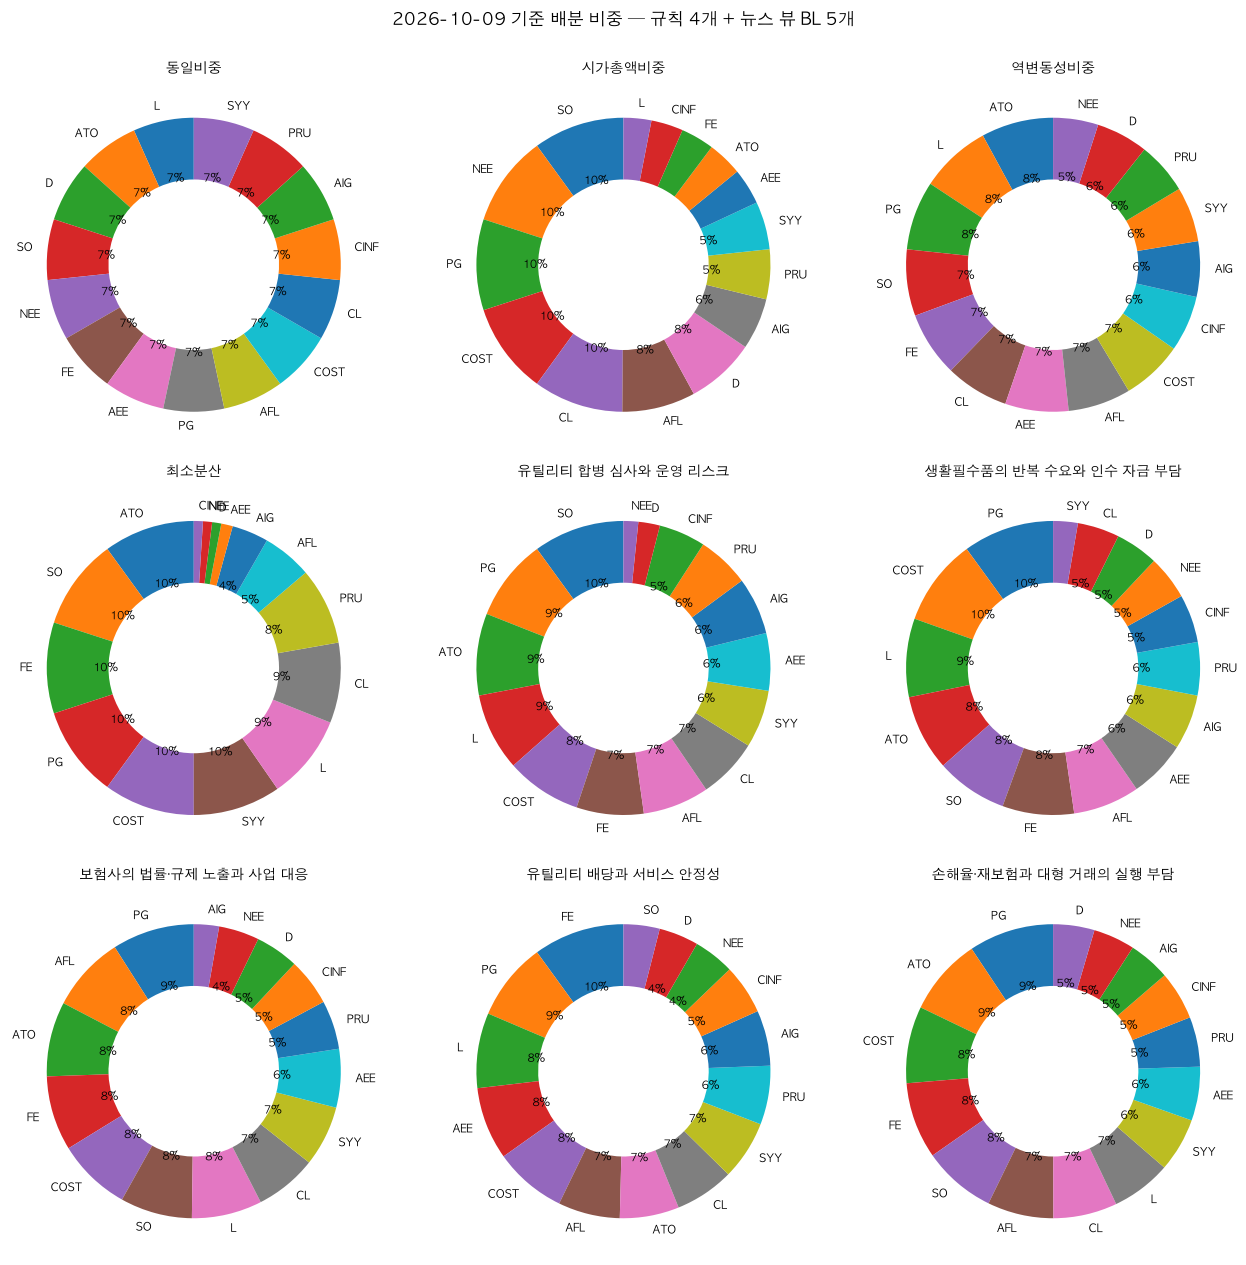

,비중,USD,원화
티커,,,
SO,10.0%,"2,238.77","3,000,001"
PG,9.0%,"2,016.96","2,702,761"
ATO,9.0%,"2,014.94","2,700,061"
L,8.5%,"1,910.46","2,560,051"
COST,8.3%,"1,857.87","2,489,581"
FE,7.4%,"1,653.18","2,215,290"
AFL,7.3%,"1,632.83","2,188,020"
CL,6.6%,"1,486.46","1,991,880"
SYY,6.4%,"1,421.89","1,905,360"


In [14]:
F = R["portfolio"].get("forward")
if not F:
    print("현재 구성 결과 없음")
else:
    nw = F.get("news_window"); print(f"기준일 {F['as_of']} · 뉴스 창 {nw['window'][0]}~{nw['window'][1]} · 기사 {nw['n_articles']}건 · 뉴스 있는 종목 {nw['n_tickers_with_news']} · δ={F['market_model']['delta']} ({F['market_model']['delta_source']})" if nw else f"기준일 {F['as_of']}")
    sc = pd.DataFrame([{"시나리오": p["title_ko"], "관점": p["portfolio_view"].split("\n")[0][:120], "뷰": " / ".join(v["summary_ko"].split(" — ")[0] for v in p["views_applied"]),
                        "근거 수": len({i for v in p["views_applied"] for i in v.get("evidence_ids", [])}), "최대 변화": max(abs(x) for x in p["delta_vs_baseline"].values()), "예상 수익": p["ex_ante"]["exp_return"], "예상 변동성": p["ex_ante"]["vol"]} for p in F["portfolios"]])
    display(sc.set_index("시나리오").style.format({"최대 변화": "{:+.1%}", "예상 수익": "{:.1%}", "예상 변동성": "{:.1%}"}))
    ports = F["templates"] + F["portfolios"]
    cols = 3; rows_ = -(-len(ports) // cols)
    fig, axes = plt.subplots(rows_, cols, figsize=(13, 4.2 * rows_))
    for ax, p in zip(axes.flat, ports):
        items = sorted([(t, w) for t, w in p["weights"].items() if w > 1e-6], key=lambda x: -x[1])
        ax.pie([w for _, w in items], labels=[t for t, _ in items], startangle=90, wedgeprops=dict(width=0.42), textprops={"fontsize": 8}, autopct=lambda v: f"{v:.0f}%" if v > 4 else "")
        ax.set_title(p.get("title_ko") or p["name_ko"], fontsize=10)
    for ax in list(axes.flat)[len(ports):]: ax.axis("off")
    plt.suptitle(f"{F['as_of']} 기준 배분 비중 — 규칙 4개 + 뉴스 뷰 BL {len(F['portfolios'])}개", y=1.0); plt.tight_layout(); plt.show()
    chosen = F["portfolios"][0] if F["portfolios"] else F["templates"][0]
    display(pd.DataFrame(chosen["allocation"]).rename(columns={"ticker": "티커", "weight": "비중", "usd": "USD", "krw": "원화"}).set_index("티커").style.format({"비중": "{:.1%}", "USD": "{:,.2f}", "원화": "{:,.0f}"}).set_caption(f"배분 금액 — {chosen['name_ko']} (투자금 {F['capital']['initial_amount_usd']:,.0f} USD)"))

## 7. 비용·조건·경고

In [15]:
u = R["llm_usage"]
if u.get("available"):
    display(pd.DataFrame(u["by_stage"]).T.style.format({"cost_usd": "{:.4f}"}).set_caption(f"분석 모델 호출 (누적, {u['model']}) — 합계 {u['total_cost_usd']:.4f} USD"))
display(pd.DataFrame(R["sources"])[["name", "what"]].rename(columns={"name": "출처", "what": "사용한 내용"}).set_index("출처"))
print("파라미터:", json.dumps(R["parameters"], ensure_ascii=False)[:600])
pd.DataFrame(R["warnings"]).rename(columns={"stage": "단계", "message": "경고"})

,calls,prompt_tokens,completion_tokens,cost_usd
02_intent,3.000000,19571.000000,6979.000000,0.0079
04_classify,6.000000,10680.000000,18045.000000,0.0114
06_explain,1.000000,950.000000,1814.000000,0.0010
00_descriptor,1.000000,3858.000000,3966.000000,0.0029
09_views,3.000000,6519.000000,9718.000000,0.0063
14a_interpret,5.000000,38034.000000,15459.000000,0.0163
14b_narrate,5.000000,79087.000000,24334.000000,0.0300
09n_wf_2026-09-08,1.000000,2887.000000,1475.000000,0.0014
09n_forward,2.000000,17043.000000,10080.000000,0.0089
09n_wf_2026-09-22,1.000000,2556.000000,1805.000000,0.0015


,사용한 내용
출처,
팀 데이터베이스 price_daily,"일별 주가·수정주가·거래량 (여러 소스의 합의값 CONSENSUS 우선, 1종목·1일 1행)"
팀 데이터베이스 financials (SEC EDGAR),발행주식수 (시가총액 필터·시가총액 비중)
팀 데이터베이스 fx_daily,원/달러 환율 USDKRW (투자금 환산 기준일 종가)
Yahoo Finance (yfinance) 캐시 사본,비교지수 ETF (SPY·QQQ·XLV) — 팀 DB 미보유로 캐시 사본 사용
팀 데이터베이스 news,"종목 뉴스 헤드라인 (GOOGLE_RSS·NEWSAPI·NAVER_NEWS), 구성일 직전 14일 창"
Wikipedia,S&P 500 · NASDAQ-100 구성 종목과 GICS 세부산업
Wikipedia GICS,GICS 11 섹터 / 25 산업그룹 / 74 산업 / 163 세부산업 분류표
MyFinSight 파이프라인 계산,후보 검색·정량 스크린·비중 계산·Black-Litterman·백테스트(bt)·검증 규칙
분석 모델 (gpt-6-luna),"의도 해석, 테마 분류, 시나리오 뷰(정적 뷰는 뉴스 미연결, walk-forward·현재 구성은 DB 뉴스 근거), 리포트 서술"


파라미터: {"portfolio": {"LOOKBACK_DAYS": 756, "SHRINKAGE": "ledoit_wolf", "TAU": 0.05, "RISK_AVERSION": {"conservative": 4.0, "moderate": 2.5, "aggressive": 1.5}, "OMEGA_METHOD": "he_litterman_confidence", "CONFIDENCE_FLOOR": 0.1, "ABS_RETURN_RANGE": [-0.5, 1.0], "REL_RETURN_RANGE": [0.0, 0.5], "TEMPLATES": ["equal_weight", "market_cap", "inverse_volatility", "min_variance"]}, "backtest": {"COMMISSION_BPS": 5, "INTEGER_POSITIONS": false, "RISK_FREE_RATE": 0.04, "TRADING_DAYS": 252, "DRIFT_TOLERANCE": 0.25, "CHECKPOINT_FREQ": "rebalance", "VOL_BANDS": {"low": 0.15, "medium": 0.3, "high": 9.99}}, "llm": 


,단계,경고
0,07,"capital re-converted at 2020-01-02 FX 1153.97: 25,997 USD vs request-date 22..."
1,12,no portfolio passed the hard rules (fail counts by rule: {'R1': 14}); recomm...
2,data,"DB 동기화(2026-10-10T11:21:13): DB price_daily에 없는 유니버스 종목 3개: SKYD, TWLO, VYLR..."
3,data,DB 동기화(2026-10-10T11:21:13): 발행주식수가 DB(SEC_EDGAR)에 없는 종목 44개는 yfinance 캐시 값을 사용
4,data,DB 동기화(2026-10-10T11:21:13): 비교지수(SPY·QQQ·XLV 등)는 팀 DB에 없어 yfinance 캐시 사본을 사...
